# 03 - Baselines: persistence, ridge regression and LightGBM

**In plain words.** Before building a neural network we build three simple forecasters and measure how well each one predicts river flow 1 to 120 hours ahead. They set the *floor* the LSTM must beat, and they tell us which clues (recent flow, rain, upstream gauges) actually carry information.

1. **Persistence** - "the flow later equals the flow now." Free, and very hard to beat for the first hours.
2. **Ridge regression** - a straight-line model on rain totals, recent flow changes and upstream gauges. Trained two ways: one model **per station** (the way the WaterBench paper did it) and one **regional** model shared by all 125 stations.
3. **LightGBM** - a tree model that can bend. It gives us feature importances and **P10 / P50 / P90** forecasts (a low, middle and high estimate), which is what the gate controller will eventually use.

**What the models predict.** The *change in log flow* between now and *h* hours ahead. Predicting the change (instead of the flow itself) puts every river on the same scale, makes "no change" the natural starting guess, and means a model only earns credit for what it adds beyond persistence. We convert back to m3/s before scoring.

**Rules followed (CLAUDE.md).** Rain = `precip_local`. Scalers, thresholds and lags use **training years only**. Features are **trailing windows only** (a leakage test below proves it). Nothing is interpolated: a row is used only if its inputs and target exist. Missing flow is never filled. **The test year is never touched; every score here is on the validation year (2017).** Results are **per station**, never one pooled number.

**Three rain scenarios, always reported.** (A) *perfect* future rain: the true future rain is given to the model, an **oracle** that no real system has; (B) *degraded* future rain: the true rain times a random error, a simplified stand-in for a real forecast; (C) *no* future rain: the honest baseline. The gap between A and C shows how much skill depends on the weather forecast rather than on our model.

**Needs:** `fyp_common.py` and the files from notebooks 01-02. **Writes:** `processed/baseline_metrics_val.csv`, `processed/quantile_calibration_val.csv`, figures 19-25.

In [1]:
import os, time as _time, warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.linear_model import Ridge
import lightgbm as lgb
import fyp_common as fc

warnings.filterwarnings("ignore")
try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8C8C8C", "#8172B3"
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)
PROC, FIG = Path("processed"), Path("figures")

QUICK = os.environ.get("FYP_QUICK") == "1"       # set FYP_QUICK=1 for a fast smoke test (12 stations, few trees)
N_TREES = 60 if QUICK else 400
RIDGE_ALPHA = 1.0                                 # the paper's default; not tuned (tuning is for later, on validation only)
RIDGE_STRIDE, LGBM_STRIDE = 3, 12                 # regional models train on every 3rd / 12th hour (neighbouring hours are near-duplicates)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=150, bbox_inches="tight"); plt.show()

g = fc.load_grid(".")
SEL = list(range(12)) if QUICK else list(range(len(g.stations)))
S, V, TR = len(SEL), g.origins["val"], g.origins["train"]
nV = len(V)
sid = [g.stations[i] for i in SEL]
sizegrp = g.size_group.iloc[SEL].to_numpy()
print(f"{'QUICK TEST: ' if QUICK else ''}{S} stations | train origins {len(TR):,} | validation origins {nV:,} | trees {N_TREES}")
print("clock: rain column used =", g.spec["clock"])

125 stations | train origins 43,392 | validation origins 8,304 | trees 400
clock: rain column used = Iowa local time; rain column to use is precip_local


## 1. Leakage test: do the features ever peek at the future?

**In plain words.** The most damaging silent bug in forecasting is a feature that accidentally contains information from *after* the moment of the forecast. The test below is blunt: take the real data, **replace everything after hour 50,000 with random garbage**, rebuild every feature for all 125 stations, and check that every feature value at or before hour 50,000 is **exactly unchanged**. If any feature had used future data, it would change.

(Hour 50,000 lies after the training years, so the scaling constants that come from training data are legitimately unaffected.)

In [2]:
import copy
T0 = 50_000
g2 = copy.copy(g); g2.Qm = g.Qm.copy(); g2.P = g.P.copy(); rng = np.random.RandomState(0)
g2.Qm[:, T0 + 1:] = rng.rand(len(g.stations), fc.N - T0 - 1) * 100
g2.P[:, T0 + 1:] = rng.rand(len(g.stations), fc.N - T0 - 1) * 10
g2.L = np.log(g2.Qm + g.eps[:, None])
changed, n_checked = [], 0
for i in range(len(g.stations)):
    a, b = fc.station_features(g, i), fc.station_features(g2, i)
    for k in a:
        n_checked += 1
        same_nan = (np.isnan(a[k][:T0 + 1]) == np.isnan(b[k][:T0 + 1])).all()
        same_val = np.nanmax(np.abs(np.nan_to_num(a[k][:T0 + 1]) - np.nan_to_num(b[k][:T0 + 1]))) < 1e-9
        if not (same_nan and same_val):
            changed.append((g.stations[i], k))
print(f"{n_checked:,} feature series checked across {len(g.stations)} stations; changed when the future was scrambled: {len(changed)}")
print("PASS - features use the past only." if not changed else f"FAIL - leakage in: {changed[:10]}")
assert not changed
del g2

5,125 feature series checked across 125 stations; changed when the future was scrambled: 0
PASS - features use the past only.


## 2. Build the modelling tables

**In plain words.** For every station and every forecast origin *t* (an hour at which we make a forecast) we build one row of clues:

- **Flow now and recently:** log flow, its change over 1/3/6/24 h, its acceleration, 1/3/7-day averages, the 24 h maximum.
- **Rain so far:** totals over the last 3, 6, 12, 24, 48, 72 and 168 h, the last hour, and two *antecedent precipitation indices* (how wet the ground already is, with a fast and a slow memory).
- **Upstream gauges** (headwater stations have none): upstream flow at **five lags** spread around the measured flood-travel time from notebook 02, plus its recent rise.
- **Calendar:** hour of day and day of year as sine/cosine pairs.
- **Catchment traits** (regional models only): area, concentration time, slope, soil fractions.
- **Future rain bins** (scenarios A and B only): rain accumulated in the next 1-3, 4-6, 7-12, 13-24, 25-48, 49-72 and 73-120 hours.

For each lead time *h* the target is `log(Q at t+h) - log(Q at t)`. Samples follow the shared split rule from notebook 02 (the whole window sits inside one split).

**Which rows count.** The ridge needs every input present, so it uses only rows where nothing is missing (headwater stations simply have no upstream columns). To keep the comparison fair, **every model, including persistence and LightGBM, is scored on exactly the same validation rows**.

In [3]:
COLS = list(fc.station_features(g, 0, static=True))
STATIC = ["log_area", "log_tc", "slope", "loam", "silt", "sandy_clay_loam", "silty_clay_loam"]
UPC = [c for c in COLS if c.startswith("Lup") or c == "dLup6"]
NONSTAT = [c for c in COLS if c not in STATIC]
FUT = [f"Pfut_{a}_{b}" for a, b in fc.FUT_BINS]
HR, HL = fc.H_RIDGE, fc.H_LGBM
print(f"{len(COLS)} base features ({len(STATIC)} static), {len(FUT)} future-rain bins, ridge lead times {HR}, LightGBM lead times {HL}")

def mat(f, cols, rows):
    return np.column_stack([f[c][rows] for c in cols]).astype(np.float32)

def ridge_prepare(X, cols, mu=None, sd=None):
    """Standardise with TRAINING statistics. Headwater stations have no upstream gauge: those columns become 0 (= the mean)."""
    if mu is None:
        mu = np.nanmean(X, axis=0); sd = np.nanstd(X, axis=0); sd = np.where(~(sd >= 1e-8), 1.0, sd)
    Z = (X - mu) / sd
    up = [j for j, c in enumerate(cols) if c in UPC]
    if up:
        hu = X[:, cols.index("has_up")] > 0.5
        Zu = Z[:, up]; Zu[~hu] = 0.0; Z[:, up] = Zu
    return Z.astype(np.float32), np.isfinite(Z).all(axis=1), mu, sd

def fit_ridge(Z, ok, Y):
    models, bounds = {}, {}
    for j, h in enumerate(HR):
        m = ok & np.isfinite(Y[:, j])
        models[h] = Ridge(alpha=RIDGE_ALPHA).fit(Z[m], Y[m, j])
        bounds[h] = (np.percentile(Y[m, j], 0.1), np.percentile(Y[m, j], 99.9))      # range of changes seen in TRAINING
    return models, bounds

def predict_ridge(fitted, Z, ok):
    models, bounds = fitted
    out = np.full((len(Z), len(HR)), np.nan, dtype=np.float32)
    if ok.any():
        for j, h in enumerate(HR):
            out[ok, j] = np.clip(models[h].predict(Z[ok]), *bounds[h])
    return out

t0 = _time.time()
TRr = TR[::RIDGE_STRIDE]
Xb_tr, Y_tr, Xfa_tr, Xfb_tr = [], [], [], []
Xb_va = np.zeros((S, nV, len(COLS)), np.float32); Xfa_va = np.zeros((S, nV, len(FUT)), np.float32); Xfb_va = np.zeros_like(Xfa_va)
okV = np.zeros((S, nV), bool)
PRED = {}                                  # (model, scenario) -> (array[S, nV, n_horizons] of predicted log-flow change, horizon list)
for sc in "ABC":
    PRED[("ridge_station", sc)] = (np.full((S, nV, len(HR)), np.nan, np.float32), HR)

for k, i in enumerate(SEL):
    f = fc.station_features(g, i, static=True)
    fut = {sc: fc.future_bins(g, i, sc) for sc in "ABC"}
    Y_all = np.column_stack([fc.target_delta(g, i, h) for h in HR]).astype(np.float32)     # (N, n_horizons)
    # regional tables (subsampled training rows, all validation rows)
    Xb_tr.append(mat(f, COLS, TRr)); Y_tr.append(Y_all[TRr])
    Xfa_tr.append(mat(fut["A"], FUT, TRr)); Xfb_tr.append(mat(fut["B"], FUT, TRr))
    Xb_va[k] = mat(f, COLS, V); Xfa_va[k] = mat(fut["A"], FUT, V); Xfb_va[k] = mat(fut["B"], FUT, V)
    # per-station ridge: every training hour, no static columns (they are constant for one station)
    for sc in "ABC":
        cols = NONSTAT + (FUT if sc != "C" else [])
        allf = {**f, **fut[sc]}
        Ztr, oktr, mu, sd = ridge_prepare(mat(allf, cols, TR), cols)
        Zva, okva, _, _ = ridge_prepare(mat(allf, cols, V), cols, mu, sd)
        models = fit_ridge(Ztr, oktr, Y_all[TR])
        PRED[("ridge_station", sc)][0][k] = predict_ridge(models, Zva, okva)
        if sc == "C":
            okV[k] = okva
Xb_tr = np.concatenate(Xb_tr); Y_tr = np.concatenate(Y_tr); Xfa_tr = np.concatenate(Xfa_tr); Xfb_tr = np.concatenate(Xfb_tr)
print(f"built tables in {_time.time() - t0:.0f} s | regional training rows {len(Xb_tr):,} | validation rows {S * nV:,}")

# which validation rows survive (all inputs present)?
mo = g.time.month.to_numpy()[V]; winter = np.isin(mo, [12, 1, 2, 3])
print(f"validation origins with all ridge inputs present: {okV.mean():.1%} overall; "
      f"Dec-Mar {okV[:, winter].mean():.1%}, other months {okV[:, ~winter].mean():.1%}")
print("by size group:", {gname: f"{okV[sizegrp == gname].mean():.0%}" for gname in ["small", "medium", "large"]})

41 base features (7 static), 7 future-rain bins, ridge lead times [1, 2, 3, 6, 9, 12, 18, 24, 36, 48, 60, 72, 96, 120], LightGBM lead times [1, 6, 12, 24, 48, 72, 120]


built tables in 22 s | regional training rows 1,808,000 | validation rows 1,038,000
validation origins with all ridge inputs present: 81.8% overall; Dec-Mar 51.4%, other months 98.1%
by size group: {'small': '85%', 'medium': '82%', 'large': '79%'}


**Read this before trusting any score.** Validation rows are only used when every input *and* the target exist. Winter flow is mostly missing (ice), so the scored rows are overwhelmingly **warm-season** rows. That is a property of the data we are allowed to use, not a bug, but it means every number below describes **spring-summer-autumn skill**. This matches the finding from notebook 02 and will matter again on the test year, where winter flow is present.

## 3. Regional ridge and LightGBM

**In plain words.** The *regional ridge* is one straight-line model per lead time, trained on all 125 stations together (catchment traits as extra inputs). Ridge predictions are **clipped to the range of log-flow changes ever seen in training** (0.1th to 99.9th percentile per lead time). Without that safeguard, a straight line fed an exaggerated rain forecast can predict an impossible surge, and converting back from logs turns it into an absurd flow (we saw exactly that in a test run). LightGBM cannot extrapolate beyond its training targets, so it needs no such safeguard. *LightGBM* builds hundreds of small decision trees; we train one model per lead time and per quantile: **P10** (a low-end estimate), **P50** (the middle) and **P90** (a high-end estimate). The gate controller will want the P90 because it errs on the side of "more water coming".

LightGBM uses scenario C (no future rain) for all three quantiles and scenarios A and B for the P50 only, to keep the run time sensible. No hyperparameter tuning here: it uses fixed, reasonable settings, because tuning belongs to its own study later (and only ever on validation data).

In [4]:
t0 = _time.time()
# ---- regional ridge, scenarios A / B / C ----
Xs = {"C": (Xb_tr, COLS), "A": (np.concatenate([Xb_tr, Xfa_tr], axis=1), COLS + FUT), "B": (np.concatenate([Xb_tr, Xfb_tr], axis=1), COLS + FUT)}
Xv = {"C": Xb_va.reshape(-1, len(COLS)),
      "A": np.concatenate([Xb_va, Xfa_va], axis=2).reshape(S * nV, -1), "B": np.concatenate([Xb_va, Xfb_va], axis=2).reshape(S * nV, -1)}
for sc in "ABC":
    X, cols = Xs[sc]
    Ztr, oktr, mu, sd = ridge_prepare(X, cols)
    models = fit_ridge(Ztr, oktr, Y_tr)
    Zva, okva, _, _ = ridge_prepare(Xv[sc], cols, mu, sd)
    PRED[("ridge_regional", sc)] = (predict_ridge(models, Zva, okva).reshape(S, nV, len(HR)), HR)
    del Ztr, Zva
print(f"regional ridge done in {_time.time() - t0:.0f} s")

# ---- LightGBM ----
t0 = _time.time()
pos = np.arange(0, len(Xb_tr), LGBM_STRIDE // RIDGE_STRIDE)       # every 12th training hour (a subset of the every-3rd-hour rows)
LG = {}
jidx = {h: HR.index(h) for h in HL}
jobs = [("lgbm_p10", "C", 0.1), ("lgbm_p50", "C", 0.5), ("lgbm_p90", "C", 0.9), ("lgbm_p50", "A", 0.5), ("lgbm_p50", "B", 0.5)]
for name, sc, alpha in jobs:
    X = Xs[sc][0][pos]
    arr = np.full((S, nV, len(HL)), np.nan, np.float32)
    for j, h in enumerate(HL):
        y = Y_tr[pos, jidx[h]]; m = np.isfinite(y)
        mdl = lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=N_TREES, learning_rate=0.05, num_leaves=63,
                                min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                n_jobs=-1, random_state=fc.SEED, verbose=-1)
        mdl.fit(X[m], y[m])
        LG[(name, sc, h)] = mdl
        arr[:, :, j] = mdl.predict(Xv[sc]).reshape(S, nV)
    PRED[(name, sc)] = (arr, HL)
    print(f"  {name} scenario {sc}: {len(HL)} lead times done ({_time.time() - t0:.0f} s elapsed)")

regional ridge done in 86 s


  lgbm_p10 scenario C: 7 lead times done (61 s elapsed)


  lgbm_p50 scenario C: 7 lead times done (125 s elapsed)


  lgbm_p90 scenario C: 7 lead times done (183 s elapsed)


  lgbm_p50 scenario A: 7 lead times done (249 s elapsed)


  lgbm_p50 scenario B: 7 lead times done (314 s elapsed)


## 4. Score everything on the same validation rows

**In plain words.** For each station and lead time we convert the predicted change in log flow back to m3/s and compare with what the river actually did. Scores:

- **NSE** (1 = perfect, 0 = no better than always guessing the average flow, negative = worse). It is dominated by big flows, so it is the headline number for floods.
- **KGE** (a similar overall score that also exposes bias and over/under-spread).
- **Flood detection at the station's own 95th-percentile line** (from training years): **POD** (share of real flood hours the model flagged), **FAR** (share of its alarms that were false), **CSI** (overall hit quality), and **flood bias** (median relative error on flood hours; negative means the model *under-predicts floods*).

Only stations with enough data are scored at each lead time. Everything is per station; we summarise with the median and the spread.

In [5]:
rows = []
for k, i in enumerate(SEL):
    Lt, Qt, eps = g.L[i][V], g.Qm[i][V], g.eps[i]
    for h in HR:
        obs = g.Qm[i, V + h]
        m = okV[k] & np.isfinite(obs) & np.isfinite(Qt)
        if not m.any():
            continue
        rows.append(dict(model="persistence", scenario="-", station=sid[k], h=h, **fc.skill(obs[m], Qt[m], g.q95[i])))
        for (mod, sc), (arr, hs) in PRED.items():
            if h not in hs:
                continue
            yh = np.clip(np.exp(Lt + arr[k, :, hs.index(h)]) - eps, 0, None)
            mm = m & np.isfinite(yh)
            rows.append(dict(model=mod, scenario=sc, station=sid[k], h=h, **fc.skill(obs[mm], yh[mm], g.q95[i])))
res = pd.DataFrame(rows)
res["size_group"] = res["station"].map(dict(zip(sid, sizegrp)))
res.to_csv(PROC / "baseline_metrics_val.csv", index=False)
print(f"{len(res):,} (model, scenario, station, lead time) scores saved to processed/baseline_metrics_val.csv")

LABEL = {("persistence", "-"): "persistence", ("ridge_station", "C"): "ridge, per station", ("ridge_regional", "C"): "ridge, regional",
         ("lgbm_p50", "C"): "LightGBM P50 (regional)"}
COLOR = {"persistence": GREY, "ridge, per station": BLUE, "ridge, regional": GREEN, "LightGBM P50 (regional)": ORANGE}
def med(model, sc, metric, by=None):
    d = res[(res.model == model) & (res.scenario == sc)]
    return d.groupby("h")[metric].median() if by is None else d[d.size_group == by].groupby("h")[metric].median()

main = pd.DataFrame({LABEL[k]: med(*k, "nse") for k in LABEL}).loc[fc.H_REPORT]
main.index.name = "lead time (h)"
display(Markdown("**Median NSE over stations, validation year, scenario C (no future rain)**"))
display(main.round(3))

16,625 (model, scenario, station, lead time) scores saved to processed/baseline_metrics_val.csv


**Median NSE over stations, validation year, scenario C (no future rain)**

,persistence,"ridge, per station","ridge, regional",LightGBM P50 (regional)
lead time (h),,,,
1,0.999,1.000,1.000,1.000
3,0.994,0.997,0.996,NaN
6,0.980,0.988,0.985,0.992
12,0.933,0.967,0.950,0.972
24,0.806,0.893,0.866,0.900
48,0.597,0.739,0.701,0.740
72,0.445,0.605,0.582,0.598
120,0.237,0.467,0.437,0.420


### 4a. Who beats persistence, and where?

**In plain words.** The gain over persistence is what a forecaster actually adds. The left plot shows the **median over stations of (model NSE minus persistence NSE)** at each lead time. The right plot shows the **share of stations where the model beats persistence**. Near zero or below 50% means the model is not yet earning its keep at that lead time.

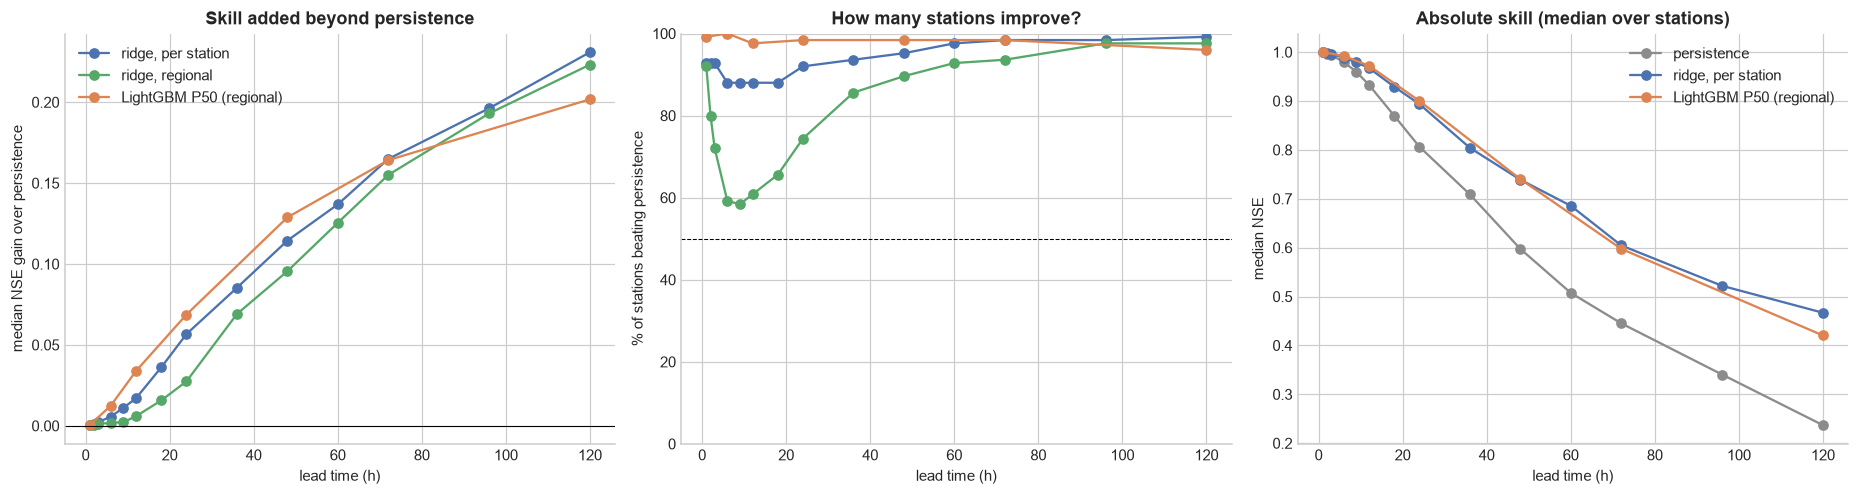

First lead time where the median gain over persistence exceeds +0.01 NSE: {'ridge, per station': 9, 'ridge, regional': 18, 'LightGBM P50 (regional)': 6}


In [6]:
pers = res[res.model == "persistence"].set_index(["station", "h"])["nse"]
def gain(model, sc):
    d = res[(res.model == model) & (res.scenario == sc)].set_index(["station", "h"])["nse"]
    return (d - pers.reindex(d.index)).dropna()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for k in LABEL:
    if k[0] == "persistence":
        continue
    gn = gain(*k); gh = gn.groupby("h")
    axes[0].plot(gh.median().index, gh.median().values, marker="o", color=COLOR[LABEL[k]], label=LABEL[k])
    axes[1].plot(gh.apply(lambda s: (s > 0).mean() * 100).index, gh.apply(lambda s: (s > 0).mean() * 100).values, marker="o", color=COLOR[LABEL[k]], label=LABEL[k])
axes[0].axhline(0, color="black", lw=0.7); axes[0].set_xlabel("lead time (h)"); axes[0].set_ylabel("median NSE gain over persistence"); axes[0].set_title("Skill added beyond persistence"); axes[0].legend()
axes[1].axhline(50, color="black", lw=0.7, ls="--"); axes[1].set_xlabel("lead time (h)"); axes[1].set_ylabel("% of stations beating persistence"); axes[1].set_title("How many stations improve?"); axes[1].set_ylim(0, 100)
for k in [("persistence", "-"), ("ridge_station", "C"), ("lgbm_p50", "C")]:
    axes[2].plot(med(*k, "nse").index, med(*k, "nse").values, marker="o", color=COLOR[LABEL[k]], label=LABEL[k])
axes[2].set_xlabel("lead time (h)"); axes[2].set_ylabel("median NSE"); axes[2].set_title("Absolute skill (median over stations)"); axes[2].legend()
savefig("19_skill_vs_persistence.png")

first_win = {}
for k in LABEL:
    if k[0] == "persistence":
        continue
    gm = gain(*k).groupby("h").median()
    first_win[LABEL[k]] = next((h for h in fc.H_RIDGE if gm.get(h, -1) > 0.01), None)
print("First lead time where the median gain over persistence exceeds +0.01 NSE:", first_win)

### 4b. Does it depend on catchment size?

**In plain words.** The same models split by the three size groups from notebook 02. We expect small, fast creeks to be the hardest, because they change faster than the lead time and depend on future rain we are not giving the model in scenario C.

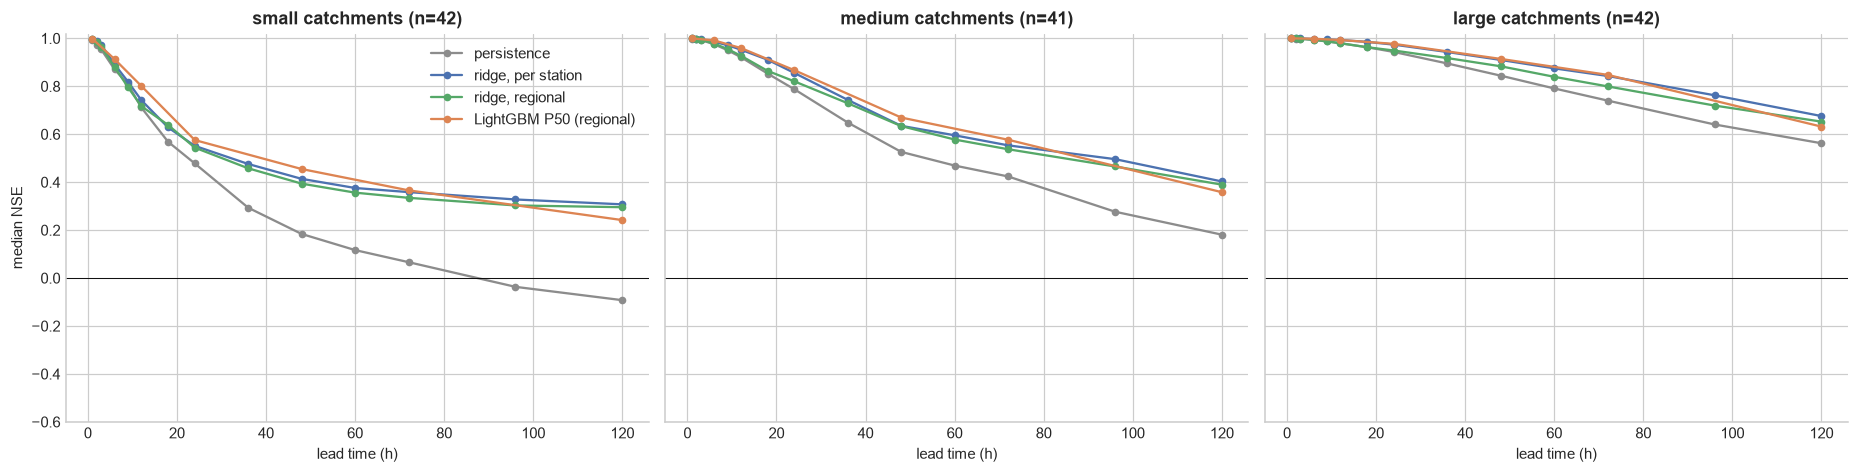

**Median NSE by size group at 6, 24 and 72 h (scenario C)**

model          lgbm_p10  lgbm_p50  lgbm_p90  persistence  ridge_regional  ridge_station
size_group h                                                                           
large      6       1.00      1.00      0.99         0.99            0.99           1.00
           24      0.95      0.98      0.92         0.94            0.95           0.97
           72      0.71      0.85      0.42         0.74            0.80           0.84
medium     6       0.98      0.99      0.96         0.98            0.98           0.99
           24      0.80      0.87      0.55         0.79            0.82           0.86
           72      0.43      0.58     -0.33         0.42            0.54           0.55
small      6       0.88      0.91      0.73         0.87            0.88           0.89
           24      0.54      0.58     -0.10         0.48            0.54           0.55
           72      0.24      0.37     -1.32         0.07            0.33           0.36

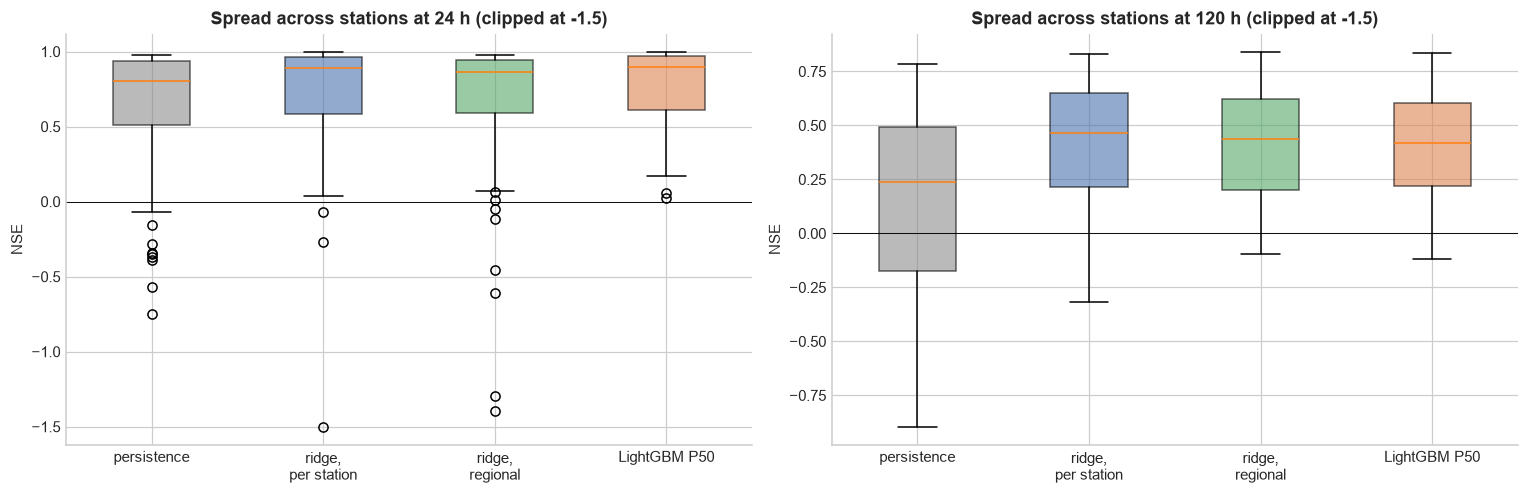

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=True)
for ax, gname in zip(axes, ["small", "medium", "large"]):
    for k in LABEL:
        s = med(*k, "nse", by=gname)
        ax.plot(s.index, s.values, marker="o", ms=4, color=COLOR[LABEL[k]], label=LABEL[k])
    ax.axhline(0, color="black", lw=0.6); ax.set_title(f"{gname} catchments (n={int((sizegrp == gname).sum())})"); ax.set_xlabel("lead time (h)")
axes[0].set_ylabel("median NSE"); axes[0].legend(); axes[0].set_ylim(-0.6, 1.02)
savefig("20_skill_by_size_group.png")

tab = res[(res.scenario.isin(["-", "C"])) & (res.h.isin([6, 24, 72]))].pivot_table(index=["size_group", "h"], columns="model", values="nse", aggfunc="median")
display(Markdown("**Median NSE by size group at 6, 24 and 72 h (scenario C)**")); display(tab.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, h in zip(axes, [24, 120]):
    data, labs = [], []
    for k in LABEL:
        d = res[(res.model == k[0]) & (res.scenario == k[1]) & (res.h == h)]["nse"].dropna().clip(lower=-1.5)
        data.append(d.values); labs.append(LABEL[k].replace(" (regional)", "").replace(", ", ",\n"))
    bp = ax.boxplot(data, tick_labels=labs, patch_artist=True, showfliers=True)
    for patch, k in zip(bp["boxes"], LABEL):
        patch.set_facecolor(COLOR[LABEL[k]]); patch.set_alpha(0.6)
    ax.axhline(0, color="black", lw=0.6); ax.set_title(f"Spread across stations at {h} h (clipped at -1.5)"); ax.set_ylabel("NSE")
savefig("21_nse_spread_across_stations.png")

## 5. Flood-specific skill

**In plain words.** A model can have a respectable overall NSE and still miss every flood, because most hours are quiet. So here we look only at the hours when the river is above its own training-year 95th percentile. A good flood forecaster flags most real floods (high POD), does not cry wolf (low FAR), and does not systematically under-predict the size of the peak (flood bias near 0). Under-prediction is the dangerous direction for a gate.

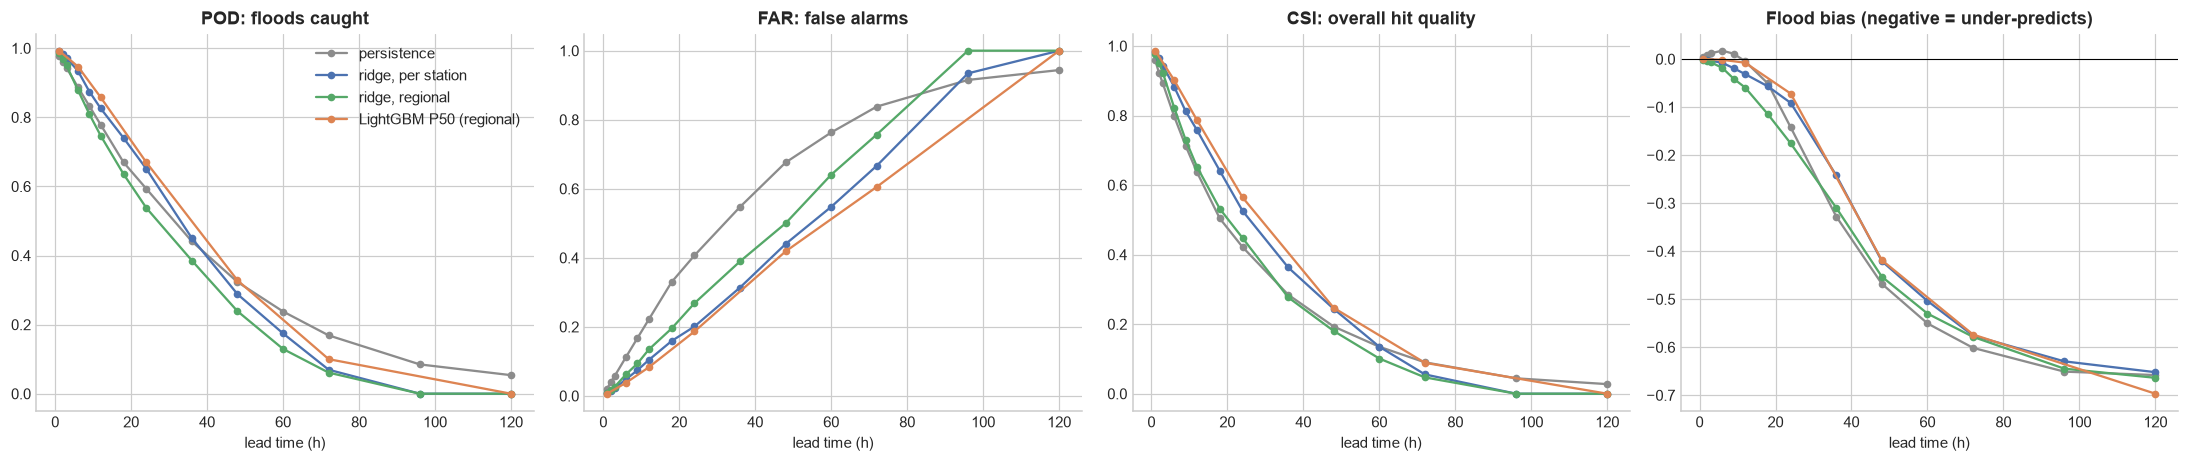

**Median flood scores at 6, 24 and 72 h (scenario C)**

csi                                                            flood_bias                                                                 pod           \
model lgbm_p10 lgbm_p50 lgbm_p90 persistence ridge_regional ridge_station   lgbm_p10 lgbm_p50 lgbm_p90 persistence ridge_regional ridge_station lgbm_p10 lgbm_p50   
h                                                                                                                                                                   
6         0.84     0.90     0.82        0.80           0.82          0.88      -0.04    -0.00     0.04        0.02          -0.02         -0.01     0.84     0.95   
24        0.34     0.56     0.42        0.42           0.45          0.53      -0.27    -0.07     0.10       -0.14          -0.18         -0.09     0.35     0.67   
72        0.00     0.09     0.15        0.09           0.05          0.06      -0.69    -0.57    -0.27       -0.60          -0.58         -0.58     0.00     0.10   

                                                         
model lgbm_p90 persistence ridge_regional ridge_station  
h                                                        
6         0.99        0.89           0.88          0.93  
24        0.86        0.59           0.54          0.65  
72        0.48        0.17           0.06          0.07

Stations with enough flood hours to score (>= 15) at 24 h: 114 of 125


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.3))
for metric, ax, ttl in zip(["pod", "far", "csi", "flood_bias"], axes, ["POD: floods caught", "FAR: false alarms", "CSI: overall hit quality", "Flood bias (negative = under-predicts)"]):
    for k in LABEL:
        s = med(*k, metric)
        ax.plot(s.index, s.values, marker="o", ms=4, color=COLOR[LABEL[k]], label=LABEL[k])
    ax.set_title(ttl); ax.set_xlabel("lead time (h)")
    if metric == "flood_bias": ax.axhline(0, color="black", lw=0.7)
axes[0].legend()
savefig("22_flood_skill.png")
fl = res[(res.scenario.isin(["-", "C"])) & (res.h.isin([6, 24, 72]))].pivot_table(index="h", columns="model", values=["pod", "csi", "flood_bias"], aggfunc="median")
display(Markdown("**Median flood scores at 6, 24 and 72 h (scenario C)**")); display(fl.round(2))
print("Stations with enough flood hours to score (>= 15) at 24 h:", int(res[(res.model == "persistence") & (res.h == 24)]["pod"].notna().sum()), "of", S)

## 6. How much of the skill comes from knowing future rain? (scenarios A, B, C)

**In plain words.** The three lines per model are: **A** the true future rain handed over (an oracle); **B** the true rain multiplied by a random error (a crude stand-in for an imperfect weather forecast: each future bin is scaled by a lognormal factor with spread 0.7, and no timing error is modelled); **C** no future rain. The gap between A and C is the *most skill any rain forecast could possibly add*. The gap between B and C is what a *mediocre* forecast adds. If B is close to C, a mediocre rain forecast is nearly worthless to us. **B is only a simplified stand-in; a real forecast archive (HRRR) is the proper test later.**

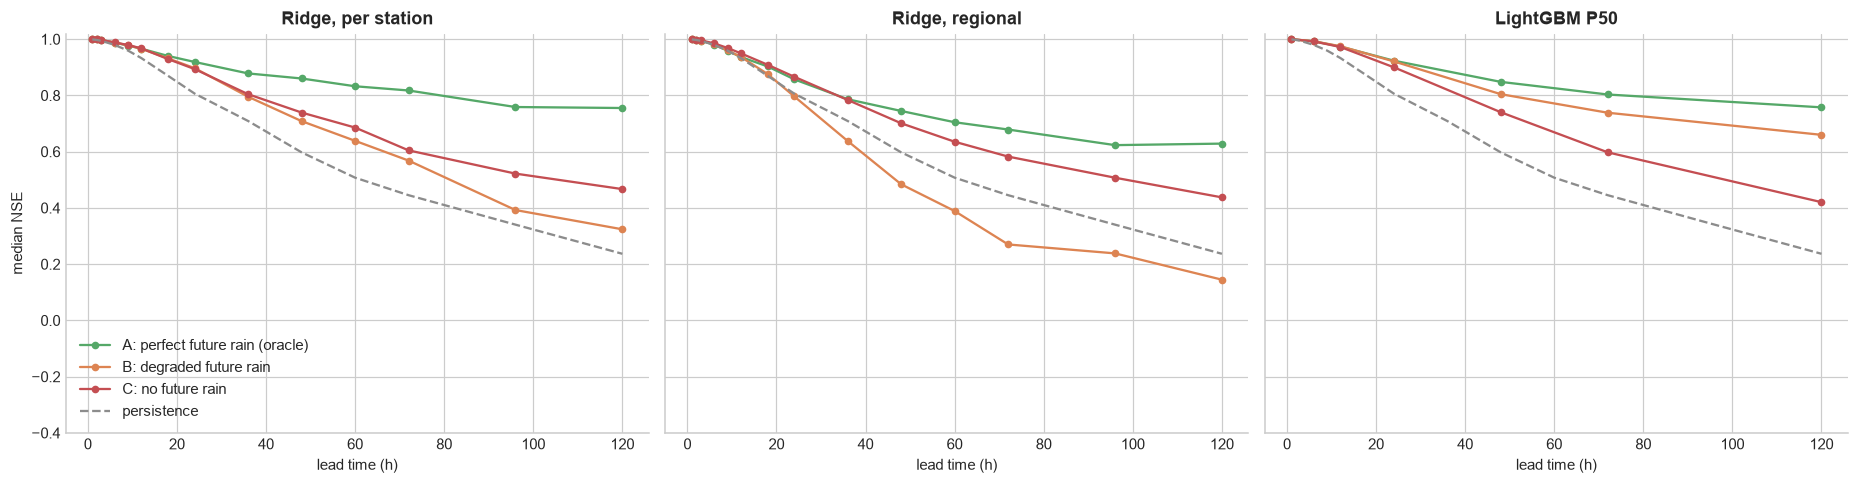

**Median NSE by rain scenario**

ridge_station               lgbm_p50              
                A      B      C        A      B      C
h                                                     
6           0.988  0.988  0.988    0.992  0.993  0.992
12          0.966  0.966  0.967    0.974  0.975  0.972
24          0.919  0.897  0.893    0.923  0.921  0.900
48          0.860  0.708  0.739    0.848  0.804  0.740
72          0.817  0.568  0.605    0.803  0.738  0.598
120         0.755  0.324  0.467    0.757  0.660  0.420

LightGBM P50: gain from the perfect rain oracle (A - C) by lead time: {6: 0.0, 12: 0.0, 24: 0.02, 48: 0.11, 72: 0.21, 120: 0.34}
LightGBM P50: gain from the degraded rain (B - C) by lead time: {6: 0.0, 12: 0.0, 24: 0.02, 48: 0.06, 72: 0.14, 120: 0.24}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, (mod, ttl) in zip(axes, [("ridge_station", "Ridge, per station"), ("ridge_regional", "Ridge, regional"), ("lgbm_p50", "LightGBM P50")]):
    for sc, col, lab in [("A", GREEN, "A: perfect future rain (oracle)"), ("B", ORANGE, "B: degraded future rain"), ("C", RED, "C: no future rain")]:
        s = med(mod, sc, "nse"); ax.plot(s.index, s.values, marker="o", ms=4, color=col, label=lab)
    s = med("persistence", "-", "nse"); ax.plot(s.index, s.values, color=GREY, ls="--", label="persistence")
    ax.set_title(ttl); ax.set_xlabel("lead time (h)")
axes[0].set_ylabel("median NSE"); axes[0].legend(); axes[0].set_ylim(-0.4, 1.02)
savefig("23_rain_scenarios.png")

sc_tab = pd.concat({m: pd.DataFrame({sc: med(m, sc, "nse") for sc in "ABC"}) for m in ["ridge_station", "lgbm_p50"]}, axis=1).loc[[6, 12, 24, 48, 72, 120]]
display(Markdown("**Median NSE by rain scenario**")); display(sc_tab.round(3))
gapAC = (sc_tab[("lgbm_p50", "A")] - sc_tab[("lgbm_p50", "C")]); gapBC = (sc_tab[("lgbm_p50", "B")] - sc_tab[("lgbm_p50", "C")])
print("LightGBM P50: gain from the perfect rain oracle (A - C) by lead time:", gapAC.round(2).to_dict())
print("LightGBM P50: gain from the degraded rain (B - C) by lead time:", gapBC.round(2).to_dict())

## 7. Are the P10 / P50 / P90 forecasts honest? (calibration)

**In plain words.** If P10 and P90 are honest, the true flow should fall *below* P10 about 10% of the time, *above* P90 about 10% of the time, and *between* them about 80% of the time. The gate controller leans on the P90, so we check two things that matter for safety:

1. **Does the P90 get exceeded about 10% of the time?** More than that means it is too optimistic.
2. **Does the P90 actually warn about floods, and at what cost?** Using the station's own 95th-percentile line as "flood": the **warning rate** is the share of real flood hours where the P90 forecast was above that line, and the **false-alarm share** is the share of P90 alarms that turned out to be nothing. (We do not ask "was the truth below P90 *given* it was a flood": a perfectly honest P90 fails that test by construction, because we would be selecting only the surprises.)

Forecasts are scenario C (no future rain), and the three quantiles are sorted so they cannot cross.

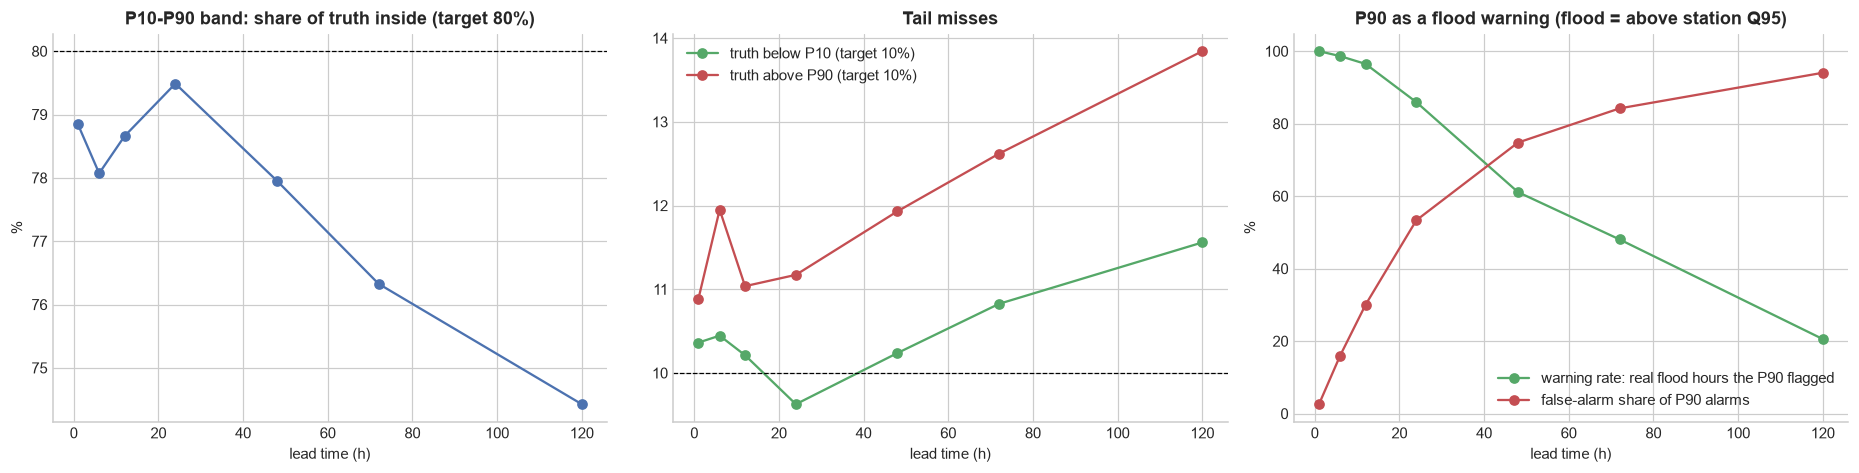

**Median calibration over stations**

,below_p10 (%),above_p90 (%),coverage_80 (%),p90_pod (%),p90_far (%)
h,,,,,
1,10.4,10.9,78.8,100.0,2.6
6,10.4,12.0,78.1,98.6,16.0
12,10.2,11.0,78.7,96.5,30.0
24,9.6,11.2,79.5,85.9,53.3
48,10.2,11.9,78.0,61.1,74.8
72,10.8,12.6,76.3,48.0,84.2
120,11.6,13.8,74.4,20.6,94.0


In [10]:
cal = []
for k, i in enumerate(SEL):
    Lt, eps = g.L[i][V], g.eps[i]
    for j, h in enumerate(HL):
        obs = g.Qm[i, V + h]
        m = okV[k] & np.isfinite(obs)
        if m.sum() < 300:
            continue
        d = np.sort(np.stack([PRED[("lgbm_p10", "C")][0][k, :, j], PRED[("lgbm_p50", "C")][0][k, :, j], PRED[("lgbm_p90", "C")][0][k, :, j]]), axis=0)
        p10, p50, p90 = [np.clip(np.exp(Lt + d[q]) - eps, 0, None)[m] for q in range(3)]
        o = obs[m]; fl = o > g.q95[i]; alarm = p90 > g.q95[i]
        cal.append(dict(station=sid[k], h=h, n=int(m.sum()), below_p10=float((o < p10).mean()), above_p90=float((o > p90).mean()),
                        coverage_80=float(((o >= p10) & (o <= p90)).mean()), p90_pod=float((p90[fl] > g.q95[i]).mean()) if fl.sum() >= 15 else np.nan,
                        p90_far=float((~fl[alarm]).mean()) if alarm.sum() >= 15 else np.nan,
                        n_flood=int(fl.sum()), rel_width=float(np.median((p90 - p10) / (p50 + eps)))))
cal = pd.DataFrame(cal); cal["size_group"] = cal["station"].map(dict(zip(sid, sizegrp)))
cal.to_csv(PROC / "quantile_calibration_val.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
cm = cal.groupby("h")[["below_p10", "above_p90", "coverage_80", "p90_pod", "p90_far"]].median()
axes[0].plot(cm.index, cm["coverage_80"] * 100, marker="o", color=BLUE); axes[0].axhline(80, color="black", ls="--", lw=0.8)
axes[0].set_title("P10-P90 band: share of truth inside (target 80%)"); axes[0].set_xlabel("lead time (h)"); axes[0].set_ylabel("%")
axes[1].plot(cm.index, cm["below_p10"] * 100, marker="o", color=GREEN, label="truth below P10 (target 10%)")
axes[1].plot(cm.index, cm["above_p90"] * 100, marker="o", color=RED, label="truth above P90 (target 10%)")
axes[1].axhline(10, color="black", ls="--", lw=0.8); axes[1].set_title("Tail misses"); axes[1].set_xlabel("lead time (h)"); axes[1].legend()
axes[2].plot(cm.index, cm["p90_pod"] * 100, marker="o", color=GREEN, label="warning rate: real flood hours the P90 flagged")
axes[2].plot(cm.index, cm["p90_far"] * 100, marker="o", color=RED, label="false-alarm share of P90 alarms")
axes[2].set_title("P90 as a flood warning (flood = above station Q95)"); axes[2].set_xlabel("lead time (h)"); axes[2].set_ylabel("%"); axes[2].legend()
savefig("24_quantile_calibration.png")
display(Markdown("**Median calibration over stations**")); display((cm * 100).round(1).rename(columns=lambda c: c + " (%)"))

## 8. What does LightGBM actually use?

**In plain words.** Feature importance (total "gain": how much each input reduced the model's error across all its trees) shows which clues matter at which lead time. A sensible model leans on the **current level and recent change in flow** for short leads and on **rain totals and upstream flow** for longer leads. If one odd feature dominates everywhere, that is a bug-smelling signal.

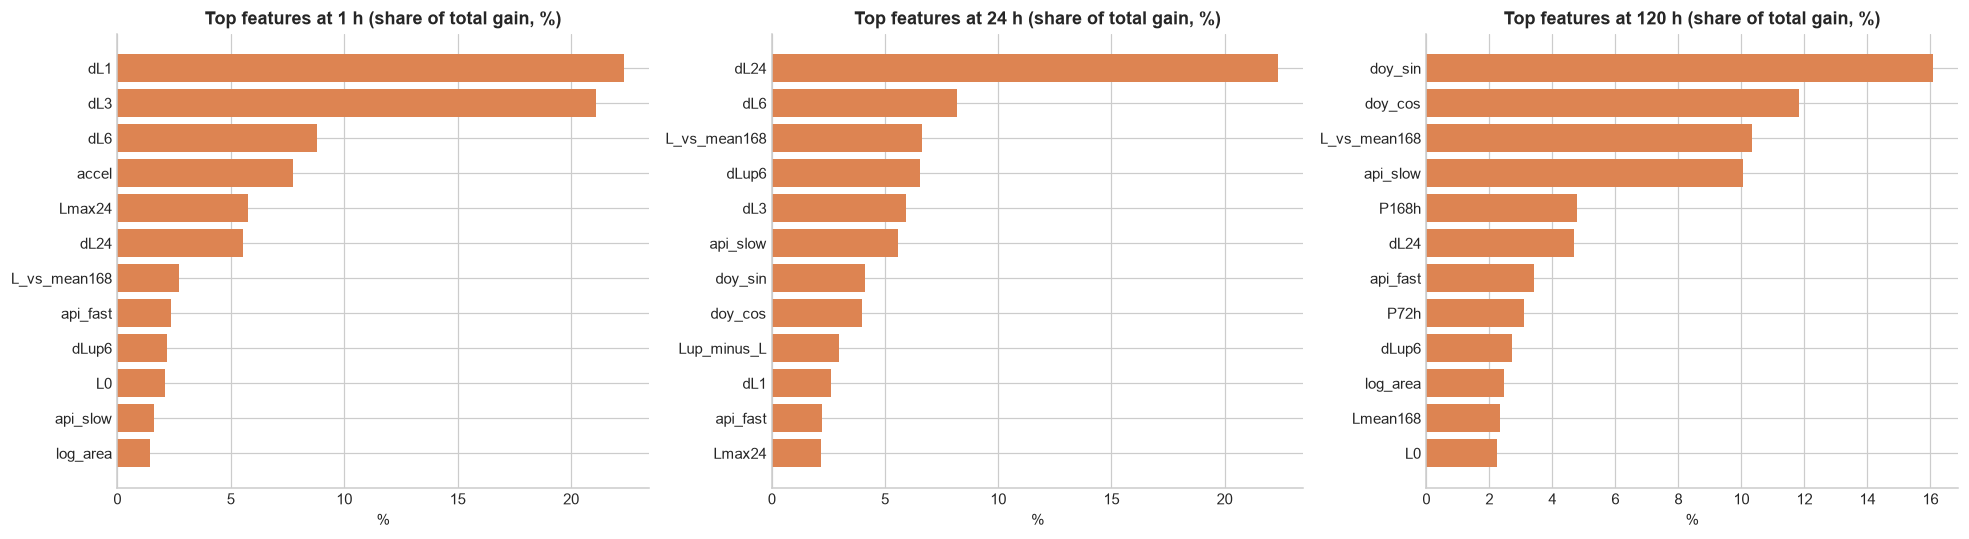

**Share of gain by feature family (%)**

,1 h,24 h,120 h
flow level/change,78.9,52.3,27.8
rain so far,8.9,18.7,27.0
upstream,4.3,11.2,5.9
calendar,1.7,8.2,27.9
catchment traits,6.2,9.6,11.3


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
imp_tbl = {}
for ax, h in zip(axes, [1, 24, 120]):
    mdl = LG[("lgbm_p50", "C", h)]
    imp = pd.Series(mdl.booster_.feature_importance("gain"), index=COLS); imp = (imp / imp.sum() * 100).sort_values(ascending=False)
    imp_tbl[h] = imp
    top = imp.head(12)[::-1]
    ax.barh(top.index, top.values, color=ORANGE); ax.set_title(f"Top features at {h} h (share of total gain, %)"); ax.set_xlabel("%")
savefig("25_lightgbm_feature_importance.png")
grp = lambda s: pd.Series({"flow level/change": s[[c for c in COLS if c.startswith(("L0", "dL", "accel", "Lmean", "Lmax", "L_vs")) and c not in UPC]].sum(),
                           "rain so far": s[[c for c in COLS if c.startswith(("P", "api", "dP"))]].sum(),
                           "upstream": s[[c for c in COLS if c in UPC or c == "has_up"]].sum(),
                           "calendar": s[[c for c in COLS if c.startswith(("hour", "doy"))]].sum(),
                           "catchment traits": s[STATIC].sum()})
display(Markdown("**Share of gain by feature family (%)**")); display(pd.DataFrame({f"{h} h": grp(imp_tbl[h]) for h in imp_tbl}).round(1))

## 9. Reproduction check against the WaterBench paper

**In plain words.** CLAUDE.md asks us to reproduce the paper's per-watershed ridge result (median NSE about 0.74, KGE about 0.79 for the 120-hour task) to prove our pipeline is sound. Three honest caveats make this a **sanity check, not an exact reproduction**:

1. The paper scores the **test year (2018)**. We must not touch it yet, so we score the **validation year (2017)**.
2. The authors' preprocessed input files are not in this project, so our inputs (our feature set, true future rain as in their benchmark, scenario A) are *similar in spirit, not identical*. The paper does not state in what way its summary number averages over the 120 lead times, so we show several readings.
3. We fit ridge at 14 lead times between 1 and 120 h, not all 120, so the "average over lead times" is approximate.

If our per-station ridge with perfect future rain lands in the same neighbourhood as the paper, the pipeline is plausible. A large gap would be a warning to investigate **before** building anything neural.

In [12]:
ra = res[(res.model == "ridge_station") & (res.scenario == "A")]
by_station = ra.groupby("station")[["nse", "kge"]].mean()                 # station average over the 14 lead times
reading = pd.DataFrame({
    "NSE": [by_station["nse"].median(), ra[ra.h == 120]["nse"].median(), ra[ra.h == 24]["nse"].median(), ra[ra.h == 1]["nse"].median()],
    "KGE": [by_station["kge"].median(), ra[ra.h == 120]["kge"].median(), ra[ra.h == 24]["kge"].median(), ra[ra.h == 1]["kge"].median()],
}, index=["median over stations of the station-mean over the 14 lead times", "median over stations at 120 h", "median over stations at 24 h", "median over stations at 1 h"])
reading.loc["PAPER (test year 2018, own inputs)"] = [0.74, 0.79]
display(reading.round(3))
ours = reading.iloc[0, 0]
print(f"Our reading closest to a lead-time average: NSE {ours:.2f} vs the paper's 0.74 (difference {ours - 0.74:+.2f}).")
print("Per-station ridge, scenario C (no future rain) for comparison: station-mean NSE median =",
      round(res[(res.model == 'ridge_station') & (res.scenario == 'C')].groupby('station')['nse'].mean().median(), 3))

,NSE,KGE
median over stations of the station-mean over the 14 lead times,0.907,0.904
median over stations at 120 h,0.755,0.805
median over stations at 24 h,0.919,0.913
median over stations at 1 h,1.000,0.999
"PAPER (test year 2018, own inputs)",0.740,0.790


Our reading closest to a lead-time average: NSE 0.91 vs the paper's 0.74 (difference +0.17).
Per-station ridge, scenario C (no future rain) for comparison: station-mean NSE median = 0.826


## 10. Findings and decisions

**In plain words.** The table that turns this notebook into design choices for the LSTM notebook. All numbers are filled in from the cells above.

In [13]:
def mv(model, sc, h, metric="nse"):
    return float(med(model, sc, metric).get(h, np.nan))
fw = first_win
gA = {h: mv("lgbm_p50", "A", h) - mv("lgbm_p50", "C", h) for h in (6, 24, 72)}
gB = {h: mv("lgbm_p50", "B", h) - mv("lgbm_p50", "C", h) for h in (6, 24, 72)}
reg_vs_stn = {h: mv("ridge_regional", "C", h) - mv("ridge_station", "C", h) for h in (24, 120)}
lgb_vs_ridge = {h: mv("lgbm_p50", "C", h) - mv("ridge_station", "C", h) for h in (6, 24, 120)}
cal_med = cal.groupby("h")[["above_p90", "p90_pod", "p90_far", "coverage_80"]].median()
rows_t = [
 ("Persistence floor (median NSE)", f"persistence {mv('persistence','-',1):.2f} (1 h), {mv('persistence','-',6):.2f} (6 h), {mv('persistence','-',24):.2f} (24 h), {mv('persistence','-',120):.2f} (120 h)",
  "Judge every model by its gain over persistence per station and lead time, not by raw NSE."),
 ("Where skill is added (scenario C)", f"first lead time with median gain > +0.01 NSE: {fw}",
  "Short leads (1-6 h) are essentially persistence; expect the LSTM's value from roughly the first lead time above, and report gain, not level."),
 ("Ridge vs LightGBM (scenario C, median NSE)", f"LightGBM minus per-station ridge: {lgb_vs_ridge[6]:+.2f} (6 h), {lgb_vs_ridge[24]:+.2f} (24 h), {lgb_vs_ridge[120]:+.2f} (120 h)",
  "If a tree model beats ridge clearly, non-linear structure matters, which is a reason to expect an LSTM to help; if not, the extra complexity must prove itself."),
 ("Regional vs per-station ridge", f"regional minus per-station: {reg_vs_stn[24]:+.2f} (24 h), {reg_vs_stn[120]:+.2f} (120 h)",
  "Run the LSTM both regional and per-station (the paper's regional models underperformed); this baseline shows the direction for linear models."),
 ("Value of future rain (LightGBM P50, NSE gain over scenario C)", f"perfect rain: {gA[6]:+.2f} (6 h), {gA[24]:+.2f} (24 h), {gA[72]:+.2f} (72 h); degraded rain: {gB[6]:+.2f}, {gB[24]:+.2f}, {gB[72]:+.2f}",
  "Never report perfect-rain skill as system skill. Only the C and degraded numbers are operationally honest; bring in real forecast rain (HRRR) as the proper degraded case."),
 ("Flood detection (median, 24 h, scenario C)", f"persistence POD {mv('persistence','-',24,'pod'):.2f} / CSI {mv('persistence','-',24,'csi'):.2f}; LightGBM POD {mv('lgbm_p50','C',24,'pod'):.2f} / CSI {mv('lgbm_p50','C',24,'csi'):.2f}; LightGBM flood bias {mv('lgbm_p50','C',24,'flood_bias'):+.2f}",
  "Add flood-weighted training (peak-weighted loss or quantile objective) if the median-based forecast under-predicts peaks; the control layer should use the upper quantile."),
 ("P90 honesty (LightGBM, scenario C)", f"truth above P90 in {cal_med['above_p90'].min()*100:.0f}-{cal_med['above_p90'].max()*100:.0f}% of cases (target 10%); as a flood warning the P90 catches {cal_med.loc[24,'p90_pod']*100:.0f}% of flood hours at 24 h ({cal_med.loc[120,'p90_pod']*100:.0f}% at 120 h) with {cal_med.loc[24,'p90_far']*100:.0f}% false alarms at 24 h",
  "The P90 is the candidate control input; judge it by this warning-versus-false-alarm trade-off and later by gate outcomes. If the 10% target is missed, widen it with conformal calibration."),
 ("Rows used", f"{okV.mean():.0%} of validation origins score (all inputs present); Dec-Mar {okV[:, winter].mean():.0%} vs other months {okV[:, ~winter].mean():.0%}",
  "All skill here is warm-season skill. On the test year, report skill with and without Dec-Mar, and do not claim winter performance from this notebook."),
 ("Pipeline sanity vs paper", f"per-station ridge with perfect rain: NSE {ours:.2f} vs paper 0.74 (validation vs their test year; not identical inputs)",
  "Treat as plausibility only. Resolve large gaps before trusting the neural results; an exact reproduction waits for the final test-year run."),
]
display(Markdown("| Finding | Numbers | Decision for the next notebook |\n|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in rows_t)))

| Finding | Numbers | Decision for the next notebook |
|---|---|---|
| Persistence floor (median NSE) | persistence 1.00 (1 h), 0.98 (6 h), 0.81 (24 h), 0.24 (120 h) | Judge every model by its gain over persistence per station and lead time, not by raw NSE. |
| Where skill is added (scenario C) | first lead time with median gain > +0.01 NSE: {'ridge, per station': 9, 'ridge, regional': 18, 'LightGBM P50 (regional)': 6} | Short leads (1-6 h) are essentially persistence; expect the LSTM's value from roughly the first lead time above, and report gain, not level. |
| Ridge vs LightGBM (scenario C, median NSE) | LightGBM minus per-station ridge: +0.00 (6 h), +0.01 (24 h), -0.05 (120 h) | If a tree model beats ridge clearly, non-linear structure matters, which is a reason to expect an LSTM to help; if not, the extra complexity must prove itself. |
| Regional vs per-station ridge | regional minus per-station: -0.03 (24 h), -0.03 (120 h) | Run the LSTM both regional and per-station (the paper's regional models underperformed); this baseline shows the direction for linear models. |
| Value of future rain (LightGBM P50, NSE gain over scenario C) | perfect rain: +0.00 (6 h), +0.02 (24 h), +0.21 (72 h); degraded rain: +0.00, +0.02, +0.14 | Never report perfect-rain skill as system skill. Only the C and degraded numbers are operationally honest; bring in real forecast rain (HRRR) as the proper degraded case. |
| Flood detection (median, 24 h, scenario C) | persistence POD 0.59 / CSI 0.42; LightGBM POD 0.67 / CSI 0.56; LightGBM flood bias -0.07 | Add flood-weighted training (peak-weighted loss or quantile objective) if the median-based forecast under-predicts peaks; the control layer should use the upper quantile. |
| P90 honesty (LightGBM, scenario C) | truth above P90 in 11-14% of cases (target 10%); as a flood warning the P90 catches 86% of flood hours at 24 h (21% at 120 h) with 53% false alarms at 24 h | The P90 is the candidate control input; judge it by this warning-versus-false-alarm trade-off and later by gate outcomes. If the 10% target is missed, widen it with conformal calibration. |
| Rows used | 82% of validation origins score (all inputs present); Dec-Mar 51% vs other months 98% | All skill here is warm-season skill. On the test year, report skill with and without Dec-Mar, and do not claim winter performance from this notebook. |
| Pipeline sanity vs paper | per-station ridge with perfect rain: NSE 0.91 vs paper 0.74 (validation vs their test year; not identical inputs) | Treat as plausibility only. Resolve large gaps before trusting the neural results; an exact reproduction waits for the final test-year run. |